# Vấn đề 4 – Viền tối do ống soi

**Mục tiêu:** áp dụng phương pháp xử lý ảnh cho đúng vấn đề này → train ResNet-18 **3 lần** → so sánh với baseline (không xử lý) → kết luận **cải thiện / không đổi / tệ đi** và **giải thích vì sao**.

**Cách đọc kết quả (quy tắc đặt trước khi chạy, giống mục 2.5.0 của báo cáo):**
- Mỗi cấu hình train **3 lần** (seed 42, 43, 44) để loại bỏ tính ngẫu nhiên của khởi tạo tham số, thứ tự lấy mẫu và flip.
- Δ = (cấu hình) − (baseline) **ghép cặp theo seed**, trung bình 3 seed. CI95: bootstrap 1 000 lần theo cụm `lesion_id`.
- **"CẢI THIỆN rõ" / "TỆ ĐI rõ"** chỉ khi đủ cả ba: |Δ| > std giữa 3 seed của baseline, CI95 không chứa 0, và cả 3 seed cùng dấu. Không đủ → **"không khác biệt rõ"**.
- Chọn cấu hình theo **val**; test chỉ để báo cáo. Không chọn seed hay ảnh "đẹp".

Chạy lần lượt từ trên xuống (Run All). Logic nằm trong `src/`; notebook chỉ gọi hàm và trình bày.

In [1]:
PROBLEM = "vien_toi"
import os, sys
from pathlib import Path
if not Path("archive").exists() and Path("../archive").exists():
    os.chdir("..")                        # chạy từ thư mục gốc repo
sys.path.insert(0, str(Path.cwd()))
import pandas as pd
from IPython.display import display, Markdown
from src.report import notebook_utils as U
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
P = U.PROBLEMS[PROBLEM]
NAMES = ["baseline"] + P["configs"]
print("Vấn đề:", P["name"], "| cấu hình so sánh:", NAMES)

Vấn đề: Viền tối do ống soi | cấu hình so sánh: ['baseline', 'vig_fill', 'vig_crop']


## 1. Vấn đề (từ EDA, mục 2.2)

- **Hiện tượng:** bốn góc hoặc cả viền ảnh đen kịt, phần nhìn thấy có dạng tròn/bầu dục (khung kính dermoscopy).
- **Đo bằng:** % diện tích vùng đen (mức xám ≤ 20) nối với mép ảnh, sau phép mở 15×15 để bỏ sợi lông (Ch.3 phân ngưỡng + Ch.7). **Ngưỡng cờ:** > 1% → **355/10 015 ảnh (3,5%)**; nhóm có 5,56% pixel ở mức 0–20 so với 0,018%.
- **Tác hại dự kiến:** đỉnh giả ở mức xám ≈ 0 làm lệch histogram (các phép cân bằng lược đồ dành dải mức xám cho viền); CNN có thể dùng "viền tròn" như dấu hiệu thiết bị chụp (ε² theo nguồn ảnh 0,071 > theo lớp 0,042).

In [2]:
fl = pd.read_csv("outputs/eda/image_flags.csv")
sp = pd.concat([pd.read_csv(f"outputs/splits/{s}.csv")[["image_id"]].assign(split=s) for s in ("train_fit", "val", "test")])
d = sp.merge(fl[["image_id", "dx", P["flag"]]], on="image_id")
tab = d.groupby("split")[P["flag"]].agg(["sum", "size"]).rename(columns={"sum": "số ảnh bị cờ", "size": "tổng"})
tab["%"] = (tab["số ảnh bị cờ"] / tab["tổng"] * 100).round(1)
display(tab.loc[["train_fit", "val", "test"]])
display(d[d[P["flag"]] & (d.split == "test")].dx.value_counts().rename("thành phần lớp của nhóm cờ (test)").to_frame().T)

,số ảnh bị cờ,tổng,%
split,,,
train_fit,223,6408,3.5
val,55,1603,3.4
test,77,2004,3.8


dx,nv,mel,bkl,df,bcc
thành phần lớp của nhóm cờ (test),39,18,16,2,2


## 2. Áp dụng gì? (Ch.3 phân ngưỡng, lọc Gauss + Ch.7)

Cả hai cấu hình chỉ tác động ảnh có viền (> 1% diện tích); ảnh khác giữ nguyên từng pixel.

| Cấu hình | Các bước và tham số |
|---|---|
| `vig_fill` | mask viền (ngưỡng ≤ 20 → mở 15×15 → vùng nối mép) → **tô viền bằng màu da** = trung vị RGB của dải da rộng 25 px sát viền → làm mềm biên bằng **lọc Gauss** 21×21 trên mask. Không đổi tỉ lệ tổn thương |
| `vig_crop` | thu nhỏ khung chữ nhật 4:3 đồng tâm đến khi viền đen ≤ 0,5% khung → **cắt** rồi phóng lại 600×450. Đánh đổi: tổn thương bị **phóng to**, mất da ở góc |

- **Giả thuyết (viết trước khi train):**
  - **H1:** CNN học được bỏ qua vùng đen cố định ở góc → kỳ vọng **ít thay đổi** toàn tập (chỉ 3,5% ảnh bị đổi).
  - **H2:** `vig_crop` đổi đồng thời hai yếu tố (bỏ viền **và** phóng to tổn thương) nên khó diễn giải; `vig_fill` sạch hơn về mặt thí nghiệm.

## 3. Ảnh trước / sau xử lý

Quy tắc chọn ảnh (cố định, không chọn ảnh "đẹp"): trong nhóm bị cờ ∩ `train_fit`, ảnh có chỉ số EDA gần **trung vị**, gần **phân vị 90** và **lớn nhất**. Bảng dưới: chỉ số EDA trước → sau, % ảnh còn vượt ngưỡng, % ảnh bị đổi và ΔE76 (mức đổi màu trung bình mỗi pixel) trên 100 ảnh bị cờ và 100 ảnh đối chứng (`train_fit`, rút ngẫu nhiên seed 42).

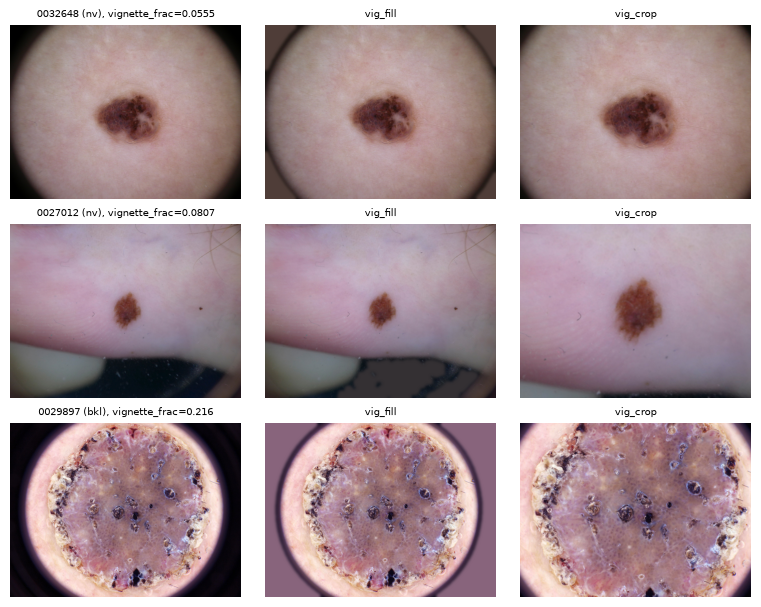

In [3]:
U.fig_before_after(PROBLEM, stem=f"{PROBLEM}_before_after");

In [4]:
display(U.image_effect(PROBLEM))

,cấu_hình,nhóm,n,vignette_frac trước (trung vị),vignette_frac sau (trung vị),% còn vượt ngưỡng,% ảnh bị đổi,ΔE76 TB
0,vig_crop,nhóm cờ,100,0.056,0.004,2.0,100.0,11.065
1,vig_crop,đối chứng,100,0.000,0.000,0.0,0.0,0.000
2,vig_fill,nhóm cờ,100,0.056,0.000,0.0,100.0,1.705
3,vig_fill,đối chứng,100,0.000,0.000,0.0,0.0,0.000


## 4. Áp dụng xử lý ảnh rồi train ResNet-18, 3 lần (seed 42, 43, 44)

- Cấu hình train **giữ nguyên siêu tham số đóng băng** của baseline (mục 2.4): ResNet-18 ImageNet, 224×224, AdamW lr 1e-4, batch 32, 20 epoch, WeightedRandomSampler, flip ngang/dọc, chọn epoch theo val macro-F1. **Chỉ thay đổi một yếu tố**: bước xử lý ảnh, áp ở 600×450 trước resize, giống nhau cho train/val/test.
- Tối ưu tốc độ cho RTX 5060 Ti (không đổi siêu tham số): `channels_last` (+26% thông lượng: 1 724 so với 1 364 ảnh/s ở batch 32), batch đánh giá 512, 32 luồng CPU khi tạo cache ảnh. Đo trên máy này: tăng batch train lên 64–512 **không** nhanh hơn (≈ 1 700–1 850 ảnh/s, GPU đã gần hết công suất tính) nên giữ batch 32.
- Thời gian: ≈ 1,5 phút/seed. Baseline (dùng chung cho 4 notebook) chỉ train một lần ở notebook chạy đầu tiên.

In [5]:
# Seed nào đã có kết quả trong outputs/runs_cl/<cấu hình>/seed*/metrics.json thì được đọc lại, không train lại.
# Ctrl+C (hoặc Interrupt kernel) an toàn: chạy lại ô này sẽ tiếp tục từ seed còn thiếu.
for name in NAMES:
    U.train(name)
display(pd.Series(U.run_info(), name="cấu hình lần chạy").to_frame())

[20:55:58] [baseline seed 42] đã có metrics.json -> đọc lại
[20:55:58] [baseline seed 43] đã có metrics.json -> đọc lại
[20:55:58] [baseline seed 44] đã có metrics.json -> đọc lại
[20:55:58] [vig_fill] nạp ảnh (cache_key=vig_fill) | split {'train': 6408, 'val': 1603, 'test': 2004} | seed cần train: [42, 43, 44]
[20:56:10] Đọc cache outputs/cache/vig_fill_224.npy ((10015, 3, 224, 224))
[20:56:24] [vig_fill seed 42] epoch  1/20 | train_loss 0.6735 | val_loss 0.6169 | val_F1 0.6405 | val_bAcc 0.7034 | 7.4s
[20:56:28] [vig_fill seed 42] epoch  2/20 | train_loss 0.3290 | val_loss 0.6478 | val_F1 0.6125 | val_bAcc 0.6614 | 4.0s
[20:56:32] [vig_fill seed 42] epoch  3/20 | train_loss 0.2419 | val_loss 0.6894 | val_F1 0.6268 | val_bAcc 0.6770 | 4.0s
[20:56:36] [vig_fill seed 42] epoch  4/20 | train_loss 0.1958 | val_loss 0.6299 | val_F1 0.6447 | val_bAcc 0.6922 | 4.0s
[20:56:40] [vig_fill seed 42] epoch  5/20 | train_loss 0.1466 | val_loss 0.5179 | val_F1 0.6795 | val_bAcc 0.6849 | 4.0s
[20:56:

,cấu hình lần chạy
model,"resnet18 (torchvision, IMAGENET1K_V1), fc -> 7..."
batch_size,32
lr,0.0001
epochs,20
seeds,"[42, 43, 44]"
env,"{'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeFor..."
channels_last,True
eval_batch,512


## 5. So sánh với baseline

### 5.1 Toàn tập: bảng và biểu đồ cột theo từng lần chạy (3 seed)

In [6]:
T = U.comparison(NAMES, "test")
Tv = U.comparison(NAMES, "val")
cols = ["cấu hình", "macro_f1_mean", "macro_f1_std", "macro_f1_per_seed", "macro_f1_delta", "macro_f1_ci_lo",
        "macro_f1_ci_hi", "macro_f1_sign", "macro_f1_verdict", "balanced_acc_delta", "balanced_acc_sign", "balanced_acc_verdict"]
print("TEST (n = 2 004)"); display(T[[c for c in cols if c in T]])
print("VAL (n = 1 603) – tập dùng để chọn cấu hình"); display(Tv[[c for c in cols if c in Tv]])

TEST (n = 2 004)


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.6808,0.0232,0.6783; 0.7052; 0.6590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,vig_fill,0.6831,0.0248,0.6695; 0.6679; 0.7117,0.0022,-0.0271,0.0362,1+/2-,không khác biệt rõ,-0.0200,1+/2-,không khác biệt rõ
2,vig_crop,0.6925,0.0059,0.6989; 0.6910; 0.6874,0.0116,-0.0127,0.0405,2+/1-,không khác biệt rõ,-0.0084,2+/1-,không khác biệt rõ


VAL (n = 1 603) – tập dùng để chọn cấu hình


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.7274,0.0095,0.7164; 0.7335; 0.7323,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,vig_fill,0.7219,0.0151,0.7045; 0.7308; 0.7304,-0.0055,-0.0298,0.0189,0+/3-,không khác biệt rõ,-0.0340,0+/3-,TỆ ĐI rõ
2,vig_crop,0.7165,0.0091,0.7080; 0.7155; 0.7261,-0.0109,-0.0349,0.0117,0+/3-,không khác biệt rõ,-0.0285,0+/3-,TỆ ĐI rõ


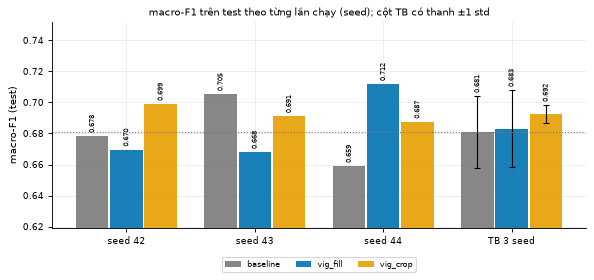

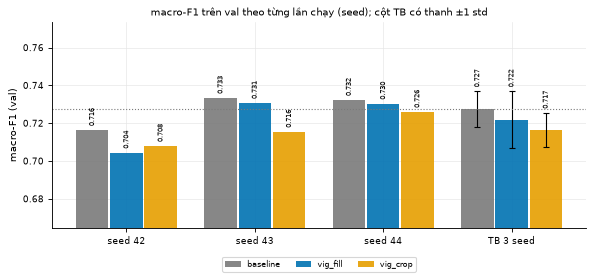

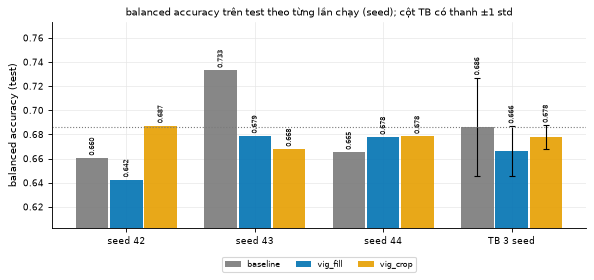

In [7]:
U.fig_seed_bars(NAMES, "test", "macro_f1", stem=f"{PROBLEM}_bars_test_macro_f1")
U.fig_seed_bars(NAMES, "val", "macro_f1", stem=f"{PROBLEM}_bars_val_macro_f1")
U.fig_seed_bars(NAMES, "test", "balanced_acc", stem=f"{PROBLEM}_bars_test_bacc");

### 5.2 Theo lớp và trên chính nhóm ảnh có vấn đề

In [8]:
print("Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)")
display(U.per_class(NAMES, "test"))
print("Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại")
display(pd.concat([U.subgroup(NAMES, P["flag"], "test"), U.subgroup(NAMES, P["flag"], "val")], ignore_index=True))

Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)


,lớp,baseline,vig_fill,vig_crop
0,akiec,0.712 ± 0.124,0.611 ± 0.035 (-0.101; 1+/2-),0.561 ± 0.040 (-0.152; 0+/2-)
1,bcc,0.754 ± 0.059,0.793 ± 0.059 (+0.039; 2+/1-),0.780 ± 0.074 (+0.026; 1+/2-)
2,bkl,0.686 ± 0.030,0.744 ± 0.093 (+0.058; 2+/1-),0.730 ± 0.064 (+0.044; 2+/1-)
3,df,0.464 ± 0.066,0.464 ± 0.025 (+0.000; 1+/2-),0.638 ± 0.050 (+0.174; 3+/0-)
4,mel,0.580 ± 0.122,0.453 ± 0.154 (-0.126; 0+/3-),0.533 ± 0.068 (-0.047; 1+/2-)
5,nv,0.895 ± 0.022,0.920 ± 0.044 (+0.025; 3+/0-),0.905 ± 0.013 (+0.010; 2+/1-)
6,vasc,0.713 ± 0.155,0.678 ± 0.087 (-0.034; 2+/1-),0.598 ± 0.087 (-0.115; 1+/2-)


Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại


,cấu hình,split,n nhóm,acc nhóm baseline,acc nhóm sau xử lý,Δ acc nhóm,CI95 Δ nhóm,dấu,Δ acc còn lại,DiD,CI95 DiD,sửa (sai→đúng) từng seed,hỏng (đúng→sai) từng seed
0,vig_fill,test,77,0.7576,0.8182,0.0606,[-0.004; +0.119],3+/0-,0.0054,0.0552,[-0.007; +0.117],10; 15; 7,2; 12; 4
1,vig_crop,test,77,0.7576,0.7965,0.0390,[-0.012; +0.089],2+/1-,0.0017,0.0372,[-0.014; +0.087],10; 11; 3,2; 6; 7
2,vig_fill,val,55,0.6667,0.6848,0.0182,[-0.052; +0.088],2+/1-,0.0006,0.0175,[-0.055; +0.087],6; 6; 8,1; 9; 7
3,vig_crop,val,55,0.6667,0.6667,0.0000,[-0.068; +0.065],1+/2-,-0.0030,0.0030,[-0.064; +0.069],6; 6; 4,4; 7; 5


### 5.3 Kết luận tự động từ số liệu (theo quy tắc ở đầu notebook)

In [9]:
for split, tab in (("test", T), ("val", Tv)):
    for name in P["configs"]:
        display(Markdown("- " + U.verdict_text(tab, name, split)))

- `vig_fill` (test): macro-F1 0.6831 ± 0.0248, Δ = +0.0022 (CI95 -0.0271; +0.0362), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0200, 1+/2- → không khác biệt rõ.

- `vig_crop` (test): macro-F1 0.6925 ± 0.0059, Δ = +0.0116 (CI95 -0.0127; +0.0405), dấu theo seed 2+/1- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0084, 2+/1- → không khác biệt rõ.

- `vig_fill` (val): macro-F1 0.7219 ± 0.0151, Δ = -0.0055 (CI95 -0.0298; +0.0189), dấu theo seed 0+/3- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0340, 0+/3- → TỆ ĐI rõ.

- `vig_crop` (val): macro-F1 0.7165 ± 0.0091, Δ = -0.0109 (CI95 -0.0349; +0.0117), dấu theo seed 0+/3- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0285, 0+/3- → TỆ ĐI rõ.

## 6. Kết luận và giải thích

**1. Áp dụng gì:** chỉ xử lý ảnh có viền đen của ống soi (3,5% ảnh). `vig_fill` **tô viền bằng màu da** (trung vị da sát viền, biên làm mềm bằng lọc Gauss). `vig_crop` **cắt bỏ viền** rồi phóng ảnh lại kích thước cũ.

**2. Kết quả: toàn tập không đổi. Trên chính nhóm có viền, `vig_fill` có tín hiệu cải thiện cùng chiều ở cả 4 phép đo qua hai lần chạy, nhưng chưa đủ bằng chứng.**
- `vig_fill`: test macro-F1 Δ **+0,002** (CI95 −0,027; +0,036), 1+/2−; val −0,006 (0+/3−). Balanced accuracy val "TỆ ĐI rõ" (−0,034); xem lưu ý chung.
- `vig_crop`: test Δ **+0,012** (−0,013; +0,041), 2+/1−; val −0,011 (0+/3−). Balanced accuracy val "TỆ ĐI rõ" (−0,029).
- **Trên chính nhóm có viền** (77 ảnh test, 55 ảnh val):
  - `vig_fill`: test **+0,061** [−0,004; +0,119], **3+/0−**; DiD +0,055 [−0,007; +0,117]; val +0,018 (2+/1−). Lần chạy trước: test +0,004, val **+0,042 (3+/0−)**. **4/4 phép đo dương**, nhưng CI đều chạm 0;
  - `vig_crop`: test +0,039, val 0,000.

**3. Vì sao:**
- **Toàn tập không đổi là đúng dự kiến (H1):** chỉ 3,5% ảnh bị đổi. Ngược lại, chính việc hai cấu hình này vẫn có balanced accuracy val "TỆ ĐI rõ" dù 96,5% ảnh giống hệt baseline cho thấy mức giảm đó chủ yếu đến từ dao động của lần chạy baseline, không phải từ phép xử lý (xem lưu ý chung).
- **Trên nhóm có viền, tô màu da có xu hướng giúp:** baseline chỉ đúng 0,758 ảnh của nhóm, thấp hơn toàn tập (0,816); sau `vig_fill` là 0,818, ngang toàn tập. Vùng đen lớn chiếm 5–20% ảnh làm lệch thống kê độ sáng mà CNN nhìn thấy sau chuẩn hóa. Nó cũng là dấu hiệu của **thiết bị chụp** chứ không phải của bệnh (EDA: viền phụ thuộc nguồn ảnh nhiều hơn phụ thuộc lớp). Tô bằng màu da biến các ảnh này thành giống ảnh không viền, vốn chiếm đa số trong tập train. Nhờ vậy mô hình xử lý chúng như phần còn lại, thay vì phải học riêng cho số ít ảnh có viền.
- **`vig_crop` kém rõ ràng hơn:** cắt viền đồng thời **phóng to tổn thương**, tức đổi luôn tỉ lệ so với ảnh khác (giả thuyết H2), nên lợi ích từ việc bỏ viền bị lẫn với tác động của việc đổi tỉ lệ.

**4. Hạn chế:** nhóm nhỏ (77 ảnh test); viền đôi khi có vành sáng (mép kính) làm màu tô bị lệch tím (mục 3); chỉ có 3 seed.

**Lưu ý chung khi đọc balanced accuracy (áp dụng cho cả 4 notebook).** Ở lần chạy này, **cả 8 cấu hình** đều có balanced accuracy val thấp hơn baseline (Δ từ −0,013 đến −0,051), và **cả 8** đều có recall `akiec` test thấp hơn baseline (−0,10 đến −0,32). Điều này xảy ra cả ở những cấu hình chỉ đổi 2,5–3,5% ảnh (`vig_fill`, `vig_crop`, `gamma_L_auto`, `flat_L_s60_cond`), tức hơn 96% ảnh train/test giống hệt baseline. Một phép xử lý chạm vào vài phần trăm ảnh khó có thể tự nó gây ra mức giảm đồng loạt như vậy. Nhiều khả năng **baseline của lần chạy này cao bất thường ở lớp nhỏ `akiec`** (recall test 0,712 ± 0,124; lần chạy trước 0,561), mà balanced accuracy lấy trung bình đều 7 lớp nên rất nhạy với lớp chỉ có 66 ảnh test. Vì vậy các kết luận "TỆ ĐI rõ" **theo balanced accuracy** cần đọc kèm lưu ý này; macro-F1 (chỉ số chính) ít bị ảnh hưởng hơn.
